# ANA500 Micro-Project 4: Forecasting Server Network Traffic with Recurrent Neural Networks
**Samuel McCauley** | October 2026

**Problem statement.** Security teams need early warning when a server's network behavior
departs from its normal pattern. This project asks whether a recurrent neural network (RNN) can
learn the normal rhythm of a server's incoming network traffic well enough to forecast it five
minutes ahead, so that large forecast errors can flag abnormal behavior for investigation.

**Hypothesis.** Incoming traffic on a production server follows a repeating time pattern (for
example, scheduled jobs), so an RNN trained only on normal traffic will forecast it far more
accurately than a naive "repeat the last value" baseline. During a real incident the pattern
breaks, forecast errors grow, and those errors can be used to detect the incident.

**Data science process:** 1. Acquire, 2. Prepare, 3. Analyze, 4. Report, 5. Act.

## Setup
Libraries used throughout: NumPy/pandas for data, Matplotlib for charts, scikit-learn for the linear benchmark, and TensorFlow/Keras for the neural networks.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"     # hide TensorFlow's startup log messages

import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import keras                                  # Keras 3 (ships with TensorFlow)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
FIG = "figures"                               # every chart is also saved here
os.makedirs(FIG, exist_ok=True)
SEEDS = [1, 2, 3]                             # fixed seeds -> reproducible results

## Step 1 - Acquire
The data comes from the **Numenta Anomaly Benchmark (NAB)**, a public research benchmark of real
streaming metrics with expert-labeled anomaly windows. The series used here,
`ec2_network_in_257a54`, is incoming network traffic (bytes) on a production Amazon EC2 server,
sampled every 5 minutes for two weeks in April 2014. Both the data and the anomaly labels are read
directly from NAB's public GitHub repository, so this notebook runs anywhere without manual
downloads.

In [2]:
BASE = "https://raw.githubusercontent.com/numenta/NAB/master"
SERIES = "realAWSCloudwatch/ec2_network_in_257a54.csv"

# Load the time series; parse_dates turns the timestamp text into real datetimes.
df = pd.read_csv(f"{BASE}/data/{SERIES}", parse_dates=["timestamp"])

# Load NAB's expert-labeled anomaly windows (a JSON file covering every NAB series)
# and keep the window(s) for this series. These are used ONLY in the Act step.
with urllib.request.urlopen(f"{BASE}/labels/combined_windows.json") as f:
    windows = json.load(f)[SERIES]
win_start, win_end = (pd.Timestamp(x) for x in windows[0])

print("Rows, columns:", df.shape)
print("Time range:", df["timestamp"].min(), "->", df["timestamp"].max())
print("Labeled anomaly window:", win_start, "->", win_end)
df.head()

Rows, columns: (4032, 2)
Time range: 2014-04-10 00:04:00 -> 2014-04-24 00:09:00
Labeled anomaly window: 2014-04-14 23:59:00 -> 2014-04-16 09:29:00


,timestamp,value
0,2014-04-10 00:04:00,251643.0
1,2014-04-10 00:09:00,3203510.0
2,2014-04-10 00:14:00,287397.0
3,2014-04-10 00:19:00,238944.0
4,2014-04-10 00:24:00,245880.0


## Step 2 - Prepare
### 2a. Data quality checks
A forecasting model assumes evenly spaced readings, so beyond missing and invalid values we also
check the time spacing between rows.

In [3]:
print("Missing values:", int(df.isna().sum().sum()))
print("Negative byte counts:", int((df["value"] < 0).sum()))      # bytes can't be negative
print("Duplicate timestamps:", int(df["timestamp"].duplicated().sum()))

# Spacing between consecutive readings: should be 5 minutes almost everywhere.
gaps = df["timestamp"].diff().dropna().value_counts()
print("Time spacing between readings:")
print(gaps)

Missing values: 0
Negative byte counts: 0
Duplicate timestamps: 0
Time spacing between readings:
timestamp
0 days 00:05:00    4029
0 days 00:10:00       2
Name: count, dtype: int64


### 2b. Transform and explore
Traffic ranges from about 40 KB to 245 MB per interval, so values are log-transformed with `log1p`
(log of 1 + value). This keeps the occasional huge spike from dominating model training. The chart
shows the full series with NAB's labeled anomaly window shaded.

Skewness  raw: 44.5   log1p: 3.19


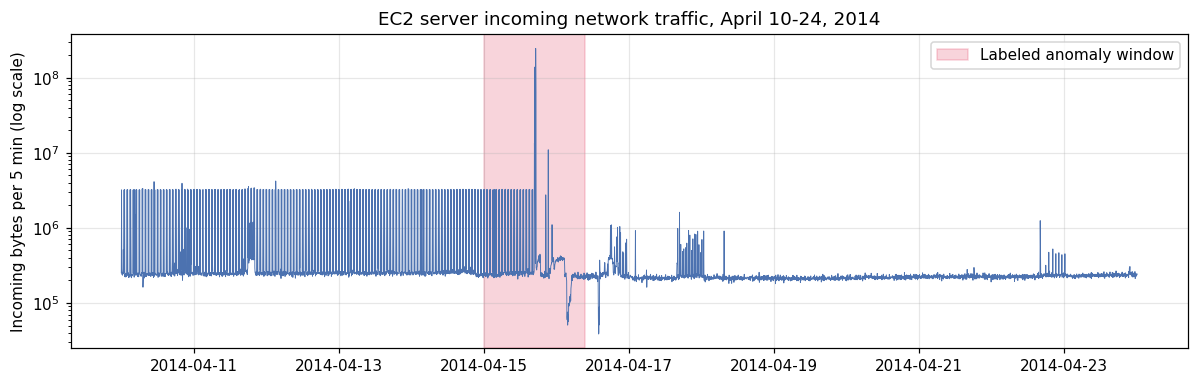

In [4]:
df["log_bytes"] = np.log1p(df["value"])
print("Skewness  raw: %.1f   log1p: %.2f" % (df["value"].skew(), df["log_bytes"].skew()))

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(df["timestamp"], df["value"], lw=0.6, color="#4C72B0")
ax.axvspan(win_start, win_end, color="crimson", alpha=0.18, label="Labeled anomaly window")
ax.set_yscale("log")
ax.set_ylabel("Incoming bytes per 5 min (log scale)")
ax.set_title("EC2 server incoming network traffic, April 10-24, 2014")
ax.legend(loc="upper right")
plt.tight_layout(); plt.savefig(f"{FIG}/01_series.png", dpi=150); plt.show()

### 2c. Is there a repeating pattern?
The chart suggests a regular burst of traffic. **Autocorrelation** measures how similar the series
is to itself shifted by a given number of steps. A strong peak at lag 12 (12 x 5 min = 1 hour)
confirms an hourly cycle, which is the kind of pattern an RNN can learn. It also tells us the input
window must span more than an hour.

Strongest lag: 12 steps (60 minutes), autocorrelation 0.93


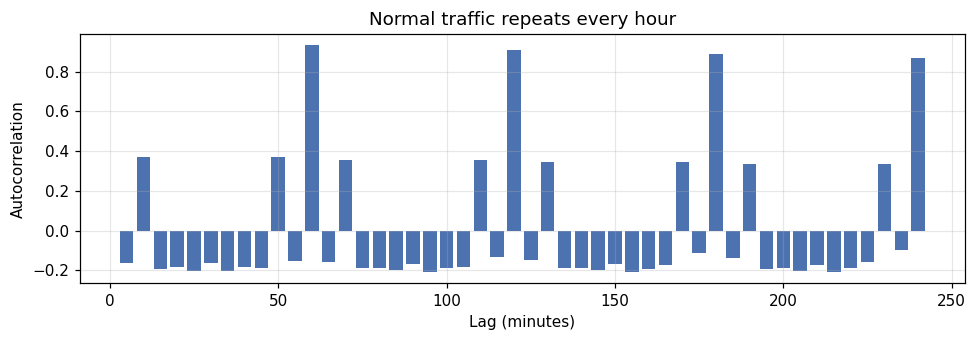

In [5]:
pre = df[df["timestamp"] < win_start]                # normal traffic before the incident
x = (pre["log_bytes"] - pre["log_bytes"].mean()).to_numpy()

# Autocorrelation for lags 1..48 (up to 4 hours), computed with NumPy.
lags = np.arange(1, 49)
acf = np.array([np.corrcoef(x[:-k], x[k:])[0, 1] for k in lags])
print("Strongest lag: %d steps (%d minutes), autocorrelation %.2f"
      % (lags[acf.argmax()], 5 * lags[acf.argmax()], acf.max()))

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(lags * 5, acf, width=4, color="#4C72B0")
ax.set_xlabel("Lag (minutes)"); ax.set_ylabel("Autocorrelation")
ax.set_title("Normal traffic repeats every hour")
plt.tight_layout(); plt.savefig(f"{FIG}/02_autocorrelation.png", dpi=150); plt.show()

### 2d. Chronological split, scaling, and sliding windows
Time series must be split **in time order**; shuffling would let a model "see the future." Only
traffic *before* the labeled incident is used to build the models (70% train, 15% validation,
15% test). Everything from the incident onward is held back for the Act step.

Each training example is a **sliding window**: the previous 24 readings (2 hours, covering two full
hourly cycles) are the input, and the next reading is the target to predict.

In [6]:
W = 24                                              # input window: 24 x 5 min = 2 hours
n_pre = int((df["timestamp"] < win_start).sum())    # rows before the incident
n_train, n_val = int(n_pre * 0.70), int(n_pre * 0.85)

# Standardize using TRAINING statistics only, so no information leaks from later data.
mu, sd = df["log_bytes"][:n_train].mean(), df["log_bytes"][:n_train].std()
z = ((df["log_bytes"] - mu) / sd).to_numpy()

# Build windows with NumPy: X[i] = previous W readings, Y[i] = the next reading.
X = np.stack([z[i - W:i] for i in range(W, len(z))])[:, :, None]   # shape (samples, W, 1)
Y = z[W:]
pos = np.arange(W, len(z))                         # row position of each target
times = df["timestamp"].to_numpy()[W:]

train = pos < n_train
val = (pos >= n_train) & (pos < n_val)
test = (pos >= n_val) & (pos < n_pre)
incident = pos >= n_pre                            # held back for the Act step
for name, m in [("train", train), ("validation", val), ("test", test), ("incident+after", incident)]:
    print(f"{name:15s} {m.sum():5d} windows")

train             981 windows
validation        216 windows
test              216 windows
incident+after   2595 windows


## Step 3 - Analyze
### 3a. Benchmarks
Every deep learning model is compared against two simpler references:
* **Persistence:** predict that the next reading equals the last one (the no-skill baseline).
* **Linear regression** on the same 24 inputs (the Micro-Project 3 technique).

Errors are reported in log units; `exp(MAE)` converts this into a "typically off by a factor of"
figure.

In [7]:
def mae(pred, mask):
    """Mean absolute error in log units, converted back from standardized scale."""
    return float(np.mean(np.abs(pred[mask] - Y[mask])) * sd)

def rmse(pred, mask):
    return float(np.sqrt(np.mean((pred[mask] - Y[mask]) ** 2)) * sd)

preds = {}
preds["Persistence (baseline)"] = X[:, -1, 0]                 # last value in each window

lin = LinearRegression().fit(X[train, :, 0], Y[train])
preds["Linear regression"] = lin.predict(X[:, :, 0])

for name in preds:
    print(f"{name:25s} validation MAE {mae(preds[name], val):.3f}")

Persistence (baseline)    validation MAE 0.888
Linear regression         validation MAE 0.152


### 3b. Deep learning models
Four neural networks with the same small size (32 units) are trained:
* **Dense network:** a standard feed-forward net that sees the 24 inputs all at once.
* **SimpleRNN, GRU, LSTM:** recurrent networks that read the window one step at a time and carry
  a memory forward. GRU and LSTM add "gates" that control what to remember and forget.

**Early stopping** halts training when validation error stops improving and restores the best
weights, which prevents overfitting. Model choice is based on **validation error only**; the test
set is used once, for the final score.

In [8]:
def build(kind):
    """Create a small Keras model of the requested kind."""
    model = keras.Sequential([keras.Input(shape=(W, 1))])
    if kind == "Dense network":
        model.add(keras.layers.Flatten())
        model.add(keras.layers.Dense(32, activation="relu"))
    else:
        layer = {"SimpleRNN": keras.layers.SimpleRNN, "GRU": keras.layers.GRU,
                 "LSTM": keras.layers.LSTM}[kind]
        model.add(layer(32))
    model.add(keras.layers.Dense(1))                  # one output: the next reading
    model.compile(optimizer="adam", loss="mse")
    return model

def train_model(kind, seed):
    keras.utils.set_random_seed(seed)                 # same seed -> same result every run
    model = build(kind)
    stop = keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)
    hist = model.fit(X[train], Y[train], validation_data=(X[val], Y[val]),
                     epochs=60, batch_size=32, verbose=0, callbacks=[stop])
    return model, hist

histories = {}
for kind in ["Dense network", "SimpleRNN", "GRU"]:
    model, histories[kind] = train_model(kind, SEEDS[0])
    preds[kind] = model.predict(X, verbose=0).ravel()
    print(f"{kind:15s} stopped after {len(histories[kind].history['loss']):2d} epochs, "
          f"validation MAE {mae(preds[kind], val):.3f}")

Dense network   stopped after 60 epochs, validation MAE 0.142


SimpleRNN       stopped after 26 epochs, validation MAE 0.134


GRU             stopped after 59 epochs, validation MAE 0.110


### 3c. LSTM ensemble
In exploratory runs averaged over three random seeds, the LSTM had the lowest validation error
of the recurrent models (0.121, vs. 0.125 for SimpleRNN and 0.126 for GRU). Single runs vary with
the random starting weights, though: in the run above, one GRU happened to score lower. That
variability is the reason for an ensemble: three LSTMs are trained with different seeds and their
forecasts are **averaged**, giving a stable, reproducible result.

In [9]:
lstm_preds = []
for seed in SEEDS:
    model, hist = train_model("LSTM", seed)
    histories[f"LSTM seed {seed}"] = hist
    lstm_preds.append(model.predict(X, verbose=0).ravel())
    print(f"LSTM seed {seed}: stopped after {len(hist.history['loss']):2d} epochs, "
          f"validation MAE {mae(lstm_preds[-1], val):.3f}")

preds["LSTM ensemble (RNN)"] = np.mean(lstm_preds, axis=0)    # average the three forecasts
print(f"LSTM ensemble validation MAE {mae(preds['LSTM ensemble (RNN)'], val):.3f}")

LSTM seed 1: stopped after 35 epochs, validation MAE 0.134


LSTM seed 2: stopped after 60 epochs, validation MAE 0.105


LSTM seed 3: stopped after 57 epochs, validation MAE 0.122
LSTM ensemble validation MAE 0.114


### 3d. Results on the held-out test period (normal traffic the models never saw)

In [10]:
results = pd.DataFrame({
    "Validation MAE": {k: mae(p, val) for k, p in preds.items()},
    "Test MAE": {k: mae(p, test) for k, p in preds.items()},
    "Test RMSE": {k: rmse(p, test) for k, p in preds.items()},
})
results["Typical error factor (test)"] = np.exp(results["Test MAE"])
base = results.loc["Persistence (baseline)", "Test MAE"]
results["Error reduction vs baseline"] = (1 - results["Test MAE"] / base).map("{:.0%}".format)
results.round(3)

,Validation MAE,Test MAE,Test RMSE,Typical error factor (test),Error reduction vs baseline
Persistence (baseline),0.888,0.891,1.469,2.438,0%
Linear regression,0.152,0.054,0.066,1.055,94%
Dense network,0.142,0.056,0.070,1.057,94%
SimpleRNN,0.134,0.055,0.070,1.057,94%
GRU,0.110,0.074,0.116,1.077,92%
LSTM ensemble (RNN),0.114,0.058,0.069,1.059,94%


## Step 4 - Report
### 4a. Learning curves
Training and validation loss for one LSTM: both fall quickly and level off together, which
indicates the model learned the pattern without memorizing the training data.

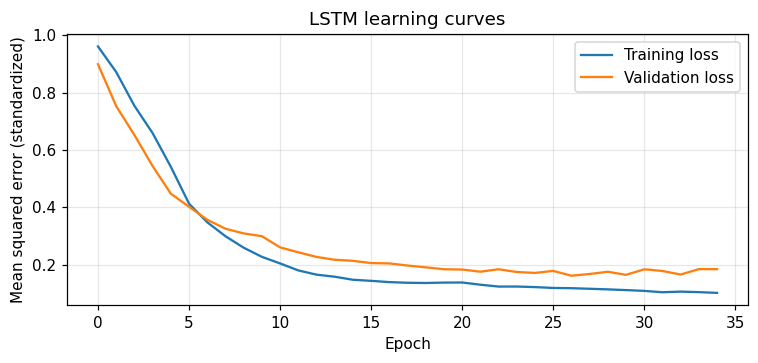

In [11]:
h = histories["LSTM seed 1"].history
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(h["loss"], label="Training loss")
ax.plot(h["val_loss"], label="Validation loss")
ax.set_xlabel("Epoch"); ax.set_ylabel("Mean squared error (standardized)")
ax.set_title("LSTM learning curves"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/03_learning_curves.png", dpi=150); plt.show()

### 4b. Model comparison

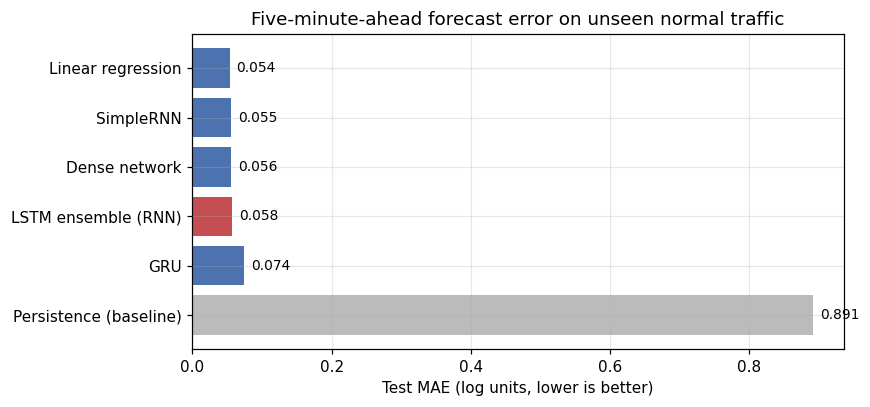

In [12]:
order = results["Test MAE"].sort_values(ascending=False)
colors = ["#BBBBBB" if "baseline" in k else "#C44E52" if "LSTM" in k else "#4C72B0"
          for k in order.index]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(order.index, order.values, color=colors)
for i, v in enumerate(order.values):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("Test MAE (log units, lower is better)")
ax.set_title("Five-minute-ahead forecast error on unseen normal traffic")
plt.tight_layout(); plt.savefig(f"{FIG}/04_model_comparison.png", dpi=150); plt.show()

### 4c. Forecast vs. actual
A 12-hour slice of the test period. The LSTM ensemble anticipates each hourly burst from the
pattern in the previous two hours; the persistence baseline can only react one step late.

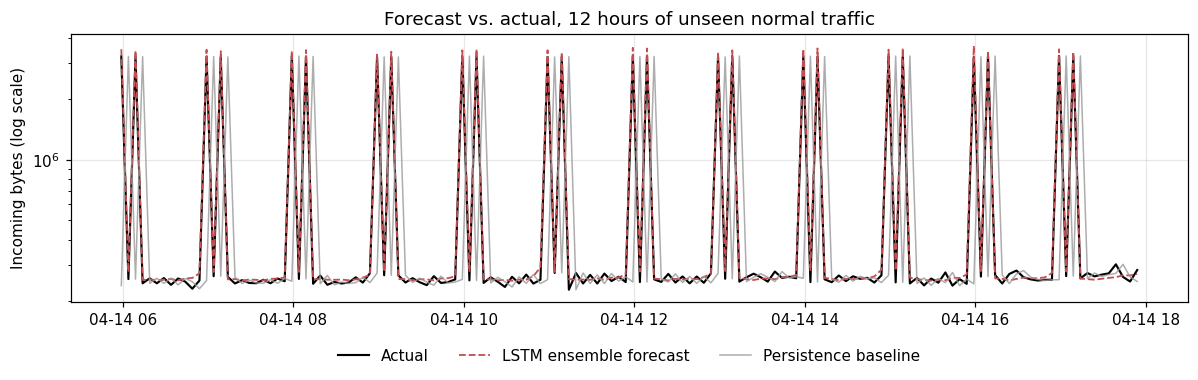

In [13]:
idx = np.where(test)[0][:144]                     # first 144 test windows = 12 hours
back = lambda p: np.expm1(p * sd + mu)             # undo standardization and log1p
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(times[idx], back(Y[idx]), color="black", lw=1.4, label="Actual")
ax.plot(times[idx], back(preds["LSTM ensemble (RNN)"][idx]), color="#C44E52", lw=1.2,
        ls="--", label="LSTM ensemble forecast")
ax.plot(times[idx], back(preds["Persistence (baseline)"][idx]), color="#999999", lw=1,
        alpha=0.8, label="Persistence baseline")
ax.set_yscale("log"); ax.set_ylabel("Incoming bytes (log scale)")
ax.set_title("Forecast vs. actual, 12 hours of unseen normal traffic")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
plt.tight_layout(); plt.savefig(f"{FIG}/05_forecast_vs_actual.png", dpi=150); plt.show()

## Step 5 - Act
### 5a. Turn forecast error into an alert
The LSTM ensemble forecasts every reading from the incident period onward. An **alert** fires when
the actual traffic differs from the forecast by more than the 99th percentile of errors seen on
normal validation traffic. Alerts within one hour of each other are grouped into a single
**alert event**, which is how an analyst would experience them.

In [14]:
err = np.abs(preds["LSTM ensemble (RNN)"] - Y) * sd           # absolute error, log units
threshold = np.percentile(err[val], 99)
alert = err > threshold
print(f"Alert threshold: {threshold:.2f} log units (actual traffic ~{np.exp(threshold):.1f}x "
      f"above or below the forecast)")

in_window = (times >= np.datetime64(win_start)) & (times <= np.datetime64(win_end))
after = incident & ~in_window

def alert_events(mask):
    """Group alert timestamps that are within 1 hour of each other into events."""
    t = pd.Series(times[mask & alert])
    if t.empty:
        return t
    new_event = t.diff().isna() | (t.diff() > pd.Timedelta("1h"))
    return t[new_event]

print(f"Normal test period: {alert[test].mean():.1%} of readings alerted, "
      f"{len(alert_events(test))} alert events")
print(f"Labeled incident window: {alert[in_window].mean():.1%} of readings alerted, "
      f"{len(alert_events(in_window))} alert events")
first = alert_events(in_window).iloc[0]
print(f"  First alert: {first}  ({(first - win_start).total_seconds() / 3600:.1f} hours "
      f"after the labeled window opens)")
peak = df.loc[(df["timestamp"] >= win_start) & (df["timestamp"] <= win_end), "value"].idxmax()
print(f"  Largest traffic surge in window: {df.loc[peak, 'timestamp']} "
      f"({df.loc[peak, 'value'] / df['value'][:n_pre].median():.0f}x normal median)")
days_after = (times[after].max() - times[after].min()) / np.timedelta64(1, "D")
print(f"After the window ({days_after:.1f} days): {alert[after].mean():.1%} of readings "
      f"alerted, {len(alert_events(after))} alert events "
      f"({len(alert_events(after)) / days_after:.1f} per day)")

Alert threshold: 1.66 log units (actual traffic ~5.3x above or below the forecast)
Normal test period: 0.0% of readings alerted, 0 alert events
Labeled incident window: 8.9% of readings alerted, 6 alert events
  First alert: 2014-04-15 03:34:00  (3.6 hours after the labeled window opens)
  Largest traffic surge in window: 2014-04-15 17:09:00 (976x normal median)
After the window (7.6 days): 0.7% of readings alerted, 7 alert events (0.9 per day)


### 5b. Alerts on the timeline

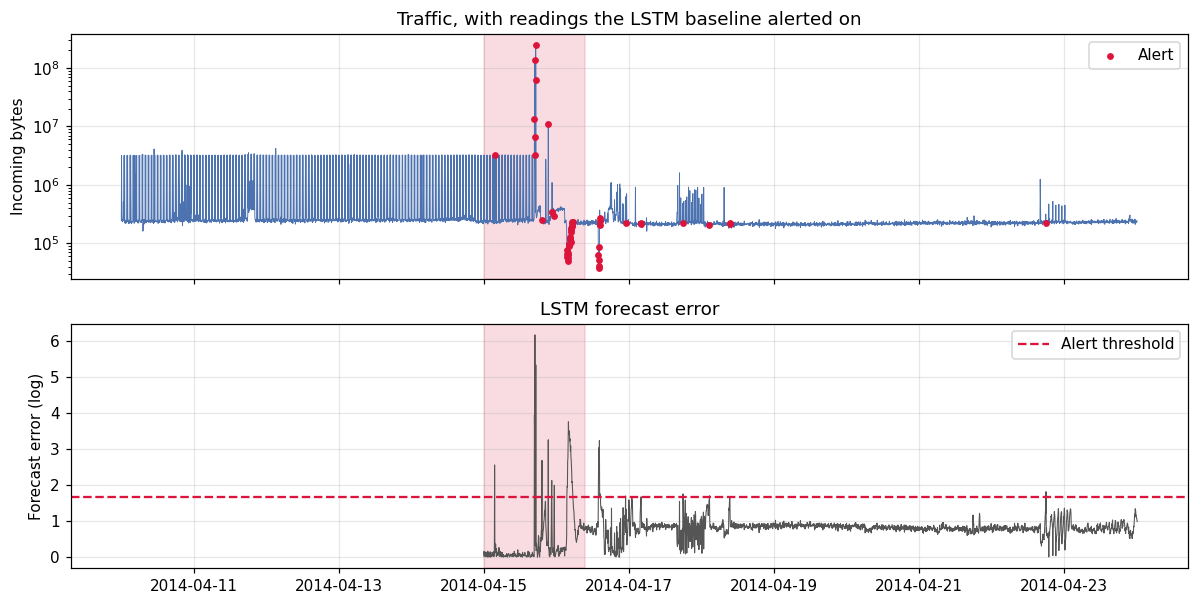

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True)
axes[0].plot(df["timestamp"], df["value"], lw=0.6, color="#4C72B0")
axes[0].set_yscale("log"); axes[0].set_ylabel("Incoming bytes")
axes[0].set_title("Traffic, with readings the LSTM baseline alerted on")
axes[0].scatter(times[alert & incident], np.expm1(Y[alert & incident] * sd + mu),
                s=12, color="crimson", zorder=3, label="Alert")
axes[1].plot(times[incident], err[incident], lw=0.7, color="#555555")
axes[1].axhline(threshold, color="crimson", ls="--", label="Alert threshold")
axes[1].set_ylabel("Forecast error (log)"); axes[1].set_title("LSTM forecast error")
for ax in axes:
    ax.axvspan(win_start, win_end, color="crimson", alpha=0.15)
    ax.legend(loc="upper right")
plt.tight_layout(); plt.savefig(f"{FIG}/06_alerts_timeline.png", dpi=150); plt.show()

### 5c. Findings and recommended actions
**Hypothesis supported.** Trained only on normal traffic, every learned model forecast the next
five minutes far more accurately than the persistence baseline (94% lower error for the LSTM
ensemble). Used as an alerting baseline, it raised no alerts during normal test traffic, and
its alerts cluster inside NAB's labeled incident window: the first came 3.6 hours into the window,
well before the 976x traffic surge on the afternoon of April 15.

**Honest caveats.**
* On this strongly repeating signal, simpler models (linear regression and a dense network)
  forecast about as well as the RNNs. The RNN's advantage is that it learns the pattern without
  being told the cycle length; on less regular traffic that advantage would matter more.
* After the incident the server's behavior changed: the hourly bursts largely stop. A model
  trained on the old pattern keeps expecting them, so its forecast error stays elevated for the
  rest of the period (lower panel above) and produces about one alert event per day. This is
  **concept drift**.

**Recommended actions for a security operations team.**
1. Deploy the forecaster as an early-warning layer on critical servers, alongside existing
   signature-based tools, routing alert events (not individual readings) to analysts.
2. After a confirmed incident or planned change, **retrain on recent normal traffic** so the
   baseline matches the server's new behavior.
3. Tune the alert threshold to analyst capacity: the 99th percentile used here trades a small
   number of false alarms for early detection.
4. Extend to more servers and metrics (CPU, outbound traffic), and retrain on a schedule.